# Feature Engineering and Baseline Model Development (ISSP)

This notebook prepares the US ISSP survey and O*NET merged dataset for modeling job satisfaction. It checks the existing cleaning and occupation-code match, builds person-job-fit features, explores associations, and compares leakage-safe classification baselines.

**Input:** `data/constructed_datasets/issp_onet_baseline_us.csv`, produced by `notebooks/constructing_datasets/missing_values_and_outliers.ipynb`. O*NET job-zone codes are independently checked against `data/formatted_onet/formatted_jobzones.csv`.

The binary outcome is `job_satisfaction >= 5` on the existing 1–7 scale. This is a modeling choice for an initial baseline, not to say that satisfaction is inherently binary.

In [2]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Load the merged data

Find the repository root from the current working directory so the notebook works when launched from either the project root or this notebook's folder. The inputs are read only; outputs are kept in memory.

In [3]:
cwd = Path.cwd().resolve()
ROOT = next(
    (parent for parent in (cwd, *cwd.parents)
     if (parent / 'data/constructed_datasets/issp_onet_baseline_us.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'Could not find data/constructed_datasets/issp_onet_baseline_us.csv '
        'in the current directory or its parents. Open the project folder as the workspace.'
    )

DATA_PATH = ROOT / 'data/constructed_datasets/issp_onet_baseline_us.csv'
JOBZONE_PATH = ROOT / 'data/formatted_onet/formatted_jobzones.csv'
df = pd.read_csv(DATA_PATH, dtype={'ONET_SOC_CODE': 'string'})
print(f'Project root: {ROOT}')
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Project root: /Users/ak101/Desktop/BTT_FALL_AI_PROJECT/Swytch-2A-predicting-job-satisfaction-from-person-job-fit
Dataset shape: 2,040 rows × 44 columns


,ONET_SOC_CODE,module_year,job_satisfaction,age,sex,marital_status,educ_years,educ_level,household_income_group,hours_worked_weekly,employment_status_current,union_member,household_size,child_in_household,urban_rural,imp_job_security,imp_income,imp_advancement,imp_interesting,imp_independence,imp_help_others,imp_useful_society,imp_decide_hours,actual_job_secure,actual_income_high,actual_advancement_high,actual_job_interesting,actual_work_independently,actual_help_others,actual_useful_society,onet_job_zone,career_interest_types_OI_artistic_value,career_interest_types_OI_conventional_value,career_interest_types_OI_enterprising_value,career_interest_types_OI_investigative_value,career_interest_types_OI_realistic_value,career_interest_types_OI_social_value,fit_gap_security,fit_gap_income,fit_gap_advancement,fit_gap_interesting,fit_gap_independence,fit_gap_help_others,fit_gap_useful_society
0,25-2056.00,1997.0,5.0,33.0,1.0,3.0,16.0,4.0,2.0,40.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,4.0,4.0,2.0,2.0,1.0,1.0,4.0,3.65,3.48,1.77,3.94,2.27,7.00,-1.0,-3.0,-2.0,0.0,0.0,1.0,1.0
1,45-2011.00,1997.0,3.0,43.0,1.0,4.0,12.0,3.0,3.0,40.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.00,5.17,3.12,4.04,5.35,1.89,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
2,17-2071.00,1997.0,4.0,45.0,1.0,3.0,15.0,4.0,3.0,50.0,1.0,3.0,1.0,2.0,1.0,2.0,2.0,3.0,2.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,4.0,2.12,4.43,2.44,5.45,6.02,1.72,-1.0,-1.0,-1.0,-2.0,0.0,-2.0,-1.0
3,11-3031.00,1997.0,1.0,42.0,1.0,1.0,16.0,4.0,1.0,50.0,1.0,3.0,5.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,4.0,1.59,5.56,7.00,2.46,1.36,3.04,0.0,0.0,0.0,-1.0,0.0,0.0,0.0
4,41-2031.00,1997.0,1.0,36.0,2.0,5.0,15.0,3.0,3.0,50.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,4.0,3.0,1.0,1.0,2.0,2.0,2.0,1.98,5.17,6.13,1.00,3.20,2.96,1.0,-2.0,-1.0,1.0,1.0,0.0,0.0


## 2. Data quality and final cleaning checks

Normalize occupation-code whitespace/case, validate the expected O*NET-SOC shape, and compare codes to the formatted O*NET job-zone lookup. Unmatched or malformed codes are reported rather than silently deleting survey records. Exact duplicate rows and rows without a usable target are removed before analysis.

In [4]:
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('\nMissing values by column (non-zero only):')
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].rename('missing_count').to_frame().assign(
    missing_pct=lambda x: (100 * x['missing_count'] / len(df)).round(1)
))

if 'ONET_SOC_CODE' not in df:
    raise KeyError('The merged input is missing required occupation key ONET_SOC_CODE.')
df['ONET_SOC_CODE'] = df['ONET_SOC_CODE'].astype('string').str.strip().str.upper()
df['ONET_SOC_CODE'] = df['ONET_SOC_CODE'].replace('', pd.NA)
onet_code_pattern = re.compile(r'^\d{2}-\d{4}\.\d{2}$')
valid_code = df['ONET_SOC_CODE'].str.fullmatch(onet_code_pattern, na=False)
print(f"\nMissing occupation codes: {df['ONET_SOC_CODE'].isna().sum():,}")
print(f'Malformed occupation codes: {(df["ONET_SOC_CODE"].notna() & ~valid_code).sum():,}')
display(df.loc[df['ONET_SOC_CODE'].notna() & ~valid_code, ['ONET_SOC_CODE']].head(10))

if JOBZONE_PATH.is_file():
    jobzones = pd.read_csv(JOBZONE_PATH, dtype={'ONET_SOC_CODE': 'string'})
    if 'ONET_SOC_CODE' not in jobzones:
        raise KeyError('The O*NET job-zone lookup is missing ONET_SOC_CODE.')
    jobzones['ONET_SOC_CODE'] = jobzones['ONET_SOC_CODE'].astype('string').str.strip().str.upper()
    lookup_codes = set(jobzones['ONET_SOC_CODE'].dropna())
    duplicate_lookup_codes = int(jobzones['ONET_SOC_CODE'].duplicated().sum())
    valid_codes = set(df.loc[valid_code, 'ONET_SOC_CODE'].dropna())
    unmatched_codes = sorted(valid_codes - lookup_codes)
    unmatched_rows = df['ONET_SOC_CODE'].isin(unmatched_codes)
    print(f'O*NET lookup rows: {len(jobzones):,}; duplicate lookup keys: {duplicate_lookup_codes:,}')
    print(f'Unique valid survey codes: {len(valid_codes):,}; unmatched unique codes: {len(unmatched_codes):,}')
    print(f'Survey rows with unmatched valid codes: {int(unmatched_rows.sum()):,}')
    display(pd.Series(unmatched_codes, name='unmatched_ONET_SOC_CODE').to_frame().head(20))
else:
    warnings.warn(f'O*NET lookup not found at {JOBZONE_PATH}; code-format validation still ran.')

Exact duplicate rows: 0

Missing values by column (non-zero only):


,missing_count,missing_pct



Missing occupation codes: 0
Malformed occupation codes: 0


,ONET_SOC_CODE


O*NET lookup rows: 923; duplicate lookup keys: 0
Unique valid survey codes: 225; unmatched unique codes: 0
Survey rows with unmatched valid codes: 0


,unmatched_ONET_SOC_CODE


In [5]:
if 'job_satisfaction' not in df:
    raise KeyError('The merged input is missing target column job_satisfaction.')
df['job_satisfaction'] = pd.to_numeric(df['job_satisfaction'], errors='coerce')
invalid_target = df['job_satisfaction'].notna() & ~df['job_satisfaction'].between(1, 7)
print('Targets outside the expected 1–7 range:', int(invalid_target.sum()))
df.loc[invalid_target, 'job_satisfaction'] = np.nan
rows_before = len(df)
df = df.dropna(subset=['job_satisfaction']).drop_duplicates().copy()
print(f'Removed {rows_before - len(df):,} rows with missing/invalid targets or exact duplicates.')

# Treat malformed occupation keys as unavailable, but retain the survey records.
df.loc[~valid_code.reindex(df.index, fill_value=False), 'ONET_SOC_CODE'] = pd.NA

# Check ranges for continuous measures; only impossible values are marked missing.
plausible_ranges = {
    'age': (14, 100),
    'hours_worked_weekly': (0, 168),
    'household_size': (1, 30),
}
for column, (low, high) in plausible_ranges.items():
    if column in df:
        df[column] = pd.to_numeric(df[column], errors='coerce')
        invalid = df[column].notna() & ~df[column].between(low, high)
        print(f'{column}: {int(invalid.sum())} values outside assumed plausible range [{low}, {high}]')
        df.loc[invalid, column] = np.nan

print(f'Analysis data shape after target/duplicate checks: {df.shape}')
display(df[['job_satisfaction']].describe().T)

Targets outside the expected 1–7 range: 0
Removed 0 rows with missing/invalid targets or exact duplicates.
age: 0 values outside assumed plausible range [14, 100]
hours_worked_weekly: 0 values outside assumed plausible range [0, 168]
household_size: 0 values outside assumed plausible range [1, 30]
Analysis data shape after target/duplicate checks: (2040, 44)


,count,mean,std,min,25%,50%,75%,max
job_satisfaction,2040.0,2.579412,1.222467,1.0,2.0,2.0,3.0,7.0


## 3. Prepare a  binary classification baseline

Class 1 is satisfaction of 5–7 and class 0 is 1–4. Respondent identifiers, the satisfaction target, and raw `ONET_SOC_CODE` are excluded: the latter would let a baseline memorize occupation labels rather than learn transferable relationships from occupation characteristics. Categorical codes are treated as categories even when stored numerically. All imputers, encoders, and scalers are fit within each model pipeline on training data only.

In [6]:
TARGET = 'job_satisfaction'
SATISFACTION_CUTOFF = 5
df['satisfied'] = (df[TARGET] >= SATISFACTION_CUTOFF).astype('int8')
print('Binary target counts (0 = 1–4, 1 = 5–7):')
display(df['satisfied'].value_counts().sort_index().rename(index={0: 'not satisfied', 1: 'satisfied'}).to_frame('count'))

categorical_candidates = [
    'module_year', 'sex', 'marital_status', 'educ_level', 'household_income_group',
    'employment_status_current', 'union_member', 'urban_rural',
]
categorical_features = [column for column in categorical_candidates if column in df.columns]
identifier_columns = {
    column for column in df.columns
    if column.upper() in {'ID', 'ID_', 'ENTITY_ID', 'RESPONDENT_ID', 'CASEID'}
    or column.upper().endswith('_ID')
}
excluded_features = {TARGET, 'satisfied', 'ONET_SOC_CODE'} | identifier_columns
feature_columns = [column for column in df.columns if column not in excluded_features]

# Convert selected coded categories to consistent strings before one-hot encoding.
X = df[feature_columns].copy()
for column in categorical_features:
    X[column] = X[column].astype('string').str.strip().replace('', pd.NA).astype(object)
    X[column] = X[column].where(pd.notna(X[column]), np.nan)
y = df['satisfied']

numeric_features = [column for column in X.select_dtypes(include='number').columns]
categorical_features = [column for column in categorical_features if column in X.columns]
unused_features = [column for column in X.columns if column not in numeric_features + categorical_features]
if unused_features:
    print('Excluding non-numeric, non-categorical columns:', unused_features)
    X = X.drop(columns=unused_features)

print(f'Predictors: {X.shape[1]} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)')
print('Excluded identifiers:', sorted(identifier_columns))
print('Raw occupation code excluded:', 'ONET_SOC_CODE' in excluded_features)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}')

Binary target counts (0 = 1–4, 1 = 5–7):


,count
satisfied,
not satisfied,1865
satisfied,175


Predictors: 42 (34 numeric, 8 categorical)
Excluded identifiers: []
Raw occupation code excluded: True
Train rows: 1,530; test rows: 510


In [8]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore')),
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features),
    ], remainder='drop')

models = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision tree': DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random forest': RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    ),
}
pipelines = {
    name: Pipeline([('preprocessor', make_preprocessor()), ('model', model)])
    for name, model in models.items()
}
print('Model pipelines are ready.')

Model pipelines are ready.


## 4. Train and compare baseline models

Accuracy is reported alongside balanced accuracy, class-1 precision/recall/F1, and ROC AUC. Because the target may be imbalanced, do not select a model by accuracy alone. This single holdout split is an initial benchmark, not a final model estimate.

,accuracy,balanced_accuracy,precision_satisfied,recall_satisfied,f1_satisfied,roc_auc
model,,,,,,
Random forest,0.851,0.774,0.326,0.682,0.441,0.807
Logistic regression,0.808,0.751,0.263,0.682,0.380,0.758
Decision tree,0.712,0.708,0.188,0.705,0.297,0.702


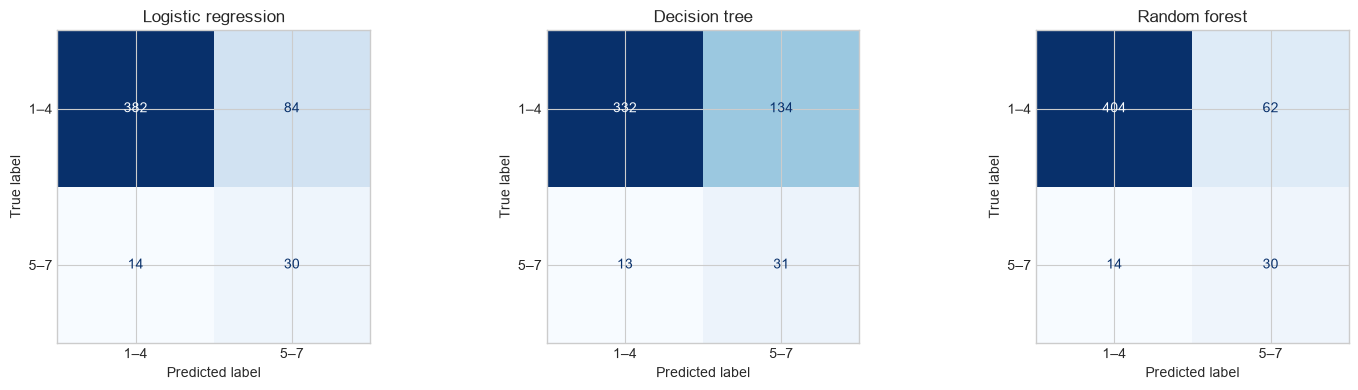

In [9]:
results = []
predictions = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions[name] = predicted
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predicted),
        'balanced_accuracy': balanced_accuracy_score(y_test, predicted),
        'precision_satisfied': precision_score(y_test, predicted, zero_division=0),
        'recall_satisfied': recall_score(y_test, predicted, zero_division=0),
        'f1_satisfied': f1_score(y_test, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_test, probabilities),
    })
results_df = pd.DataFrame(results).set_index('model').sort_values('f1_satisfied', ascending=False)
display(results_df.round(3))

fig, axes = plt.subplots(1, len(pipelines), figsize=(5 * len(pipelines), 4))
for ax, (name, predicted) in zip(np.atleast_1d(axes), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, display_labels=['1–4', '5–7'], cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [10]:
for name, pipeline in pipelines.items():
    print(f'\n{name} — test-set classification report')
    print(classification_report(y_test, predictions[name], target_names=['not satisfied (1–4)', 'satisfied (5–7)'], zero_division=0))


Logistic regression — test-set classification report
                     precision    recall  f1-score   support

not satisfied (1–4)       0.96      0.82      0.89       466
    satisfied (5–7)       0.26      0.68      0.38        44

           accuracy                           0.81       510
          macro avg       0.61      0.75      0.63       510
       weighted avg       0.90      0.81      0.84       510


Decision tree — test-set classification report
                     precision    recall  f1-score   support

not satisfied (1–4)       0.96      0.71      0.82       466
    satisfied (5–7)       0.19      0.70      0.30        44

           accuracy                           0.71       510
          macro avg       0.58      0.71      0.56       510
       weighted avg       0.90      0.71      0.77       510


Random forest — test-set classification report
                     precision    recall  f1-score   support

not satisfied (1–4)       0.97      0.87      0.91

## 5. Interpretation and Next Steps

### Key Findings

- **Severe class imbalance**: The binary target (satisfied = score ≥ 5) splits 1,865 vs. 175 — only **8.6%** of respondents fall into the satisfied class. This imbalance is the dominant challenge for this baseline and explains the gap between raw accuracy and class-1 precision across all models.
- **Random Forest performed best overall**, achieving an F1 of **0.441** and ROC AUC of **0.807** on the held-out test set (n = 510). It also had the highest balanced accuracy (0.774) and precision for the satisfied class (0.326), meaning roughly 1 in 3 positive predictions was correct.
- **High accuracy is misleading**: All models score 71–85% accuracy, but this is largely driven by correctly predicting the dominant not-satisfied class. Balanced accuracy (71–77%) gives a more honest picture of performance.

### Suggestions

1. **Repeated stratified cross-validation**: Replace the single holdout split with 5-fold or 10-fold stratified CV to get more stable performance estimates with confidence intervals.
2. `class_weight='balanced'`, to address the imbalance.
3. **Subgroup and fairness evaluation**: Check whether model performance differs across demographic groups (sex, education, income) to identify potential bias.
4. **Disclaimer**: All results describe predictive associations only — they do not establish that changing a feature would cause a change in job satisfaction.